# Эксперимент 4. Параметры майнеров и фильтр редких трасс

Вариант «категории × 2», поиск способов поднять precision моделей.

**Идея.** Журнал тот же, что в основном варианте `oldcase_x2` (29 состояний). Меняются только алгоритм и его параметры:
- **Heuristics Miner** с более строгим порогом зависимости (0.95, 0.99) и с отсечением редких дуг
  (`min_dfg_occurrences = 30`): в модель попадают только устойчивые связи; и с более строгим порогом параллельности
  (`and_threshold = 0.95`), чтобы категории реже считались параллельными;
- **Inductive Miner** с порогом шума 0.3 и 0.5;
- **обучение только на частых трассах**: модель строится по людям, чья трасса встречается хотя бы у двух человек
  (редкие, уникальные трассы не тянут в модель лишние пути); проверка — на всех людях;
- **ILP Miner** — обычно даёт самую высокую precision, но здесь не уложился даже в 6 минут на 300 людях, поэтому
  выключен флагом `RUN_ILP = False` (можно включить и оставить считаться на ночь);
- **precision через выравнивания** (alignments) для HM 0.9 (флаг `ALIGN_CASES`, считается во всех экспериментах):
  token replay может искажать precision на сетях со многими скрытыми переходами, выравнивания точнее.

**Зачем.** Понять, сколько precision можно получить без изменения журнала.

**Как запустить.** Окружение `D:\Git\diploma\.venv`, открыть ноутбук из этой папки, *Run All*. Вход — таблица этапа 0
(`jupyter lab\stage0 - data\out\compas_custody_charges.csv`), общий код журнала — `x2_common.py` рядом (тот же, что в
`oldcase_x2`). Результаты пишутся в `out\` этой папки.

**Как сравниваются модели.** Как в `oldcase_x2`: люди делятся на train 80% / test 20% (seed 42), модели строятся на
train, fitness и precision считаются token-based replay на первых 2 000 людях train и test. Базовая линия — вариант
`oldcase_x2` (29 состояний, порядок по тяжести): HM 0.9 — fitness 0.982, precision 0.543; IM 0.2 — 0.994 / 0.383.

## Шаг 0. Настройки

In [1]:
import os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")
os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "False"
for gv in [Path(r"D:\Graphviz\bin")]:
    if gv.exists() and str(gv) not in os.environ["PATH"]:
        os.environ["PATH"] = str(gv) + os.pathsep + os.environ["PATH"]
import pm4py
import x2_common as X

HERE = Path.cwd()
ROOT = HERE.parent.parent                       # jupyter lab (на компьютере) или корень репозитория
CANDIDATES = [ROOT / "stage0 - data" / "out" / "compas_custody_charges.csv",
              ROOT / "stage0-data" / "compas_custody_charges.csv"]
DATA = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])
OUT = HERE / "out"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

EXP = "x2_exp4_miners"
BUILD = {}       # параметры журнала
MERGE_RARE = False      # слить редкие OldCase: X
MIN_EVENTS = 300            # порог «редкого» состояния
MODELS = ['HM_0.9', 'HM_0.95', 'HM_0.99', 'HM_0.9_min30', 'HM_0.9_and0.95', 'IM_0.2', 'IM_0.3', 'IM_0.5', 'HM_0.9_freq', 'IM_0.2_freq', 'ILP']
EVAL_CASES = 2000           # людей в выборках train/test для fitness/precision
RUN_ILP = False             # ILP Miner (долго)
ALIGN_CASES = 2000          # precision через выравнивания для HM 0.9 на стольких людях из test (0 — не считать);
                            # чем меньше выборка, тем ниже precision (часть префиксов не встречается), поэтому 2000
print("pm4py", pm4py.__version__, "| вход:", DATA, DATA.exists())


def show(path, max_px=1400):
    from io import BytesIO
    from PIL import Image as PILImage
    PILImage.MAX_IMAGE_PIXELS = None
    im = PILImage.open(path)
    im.thumbnail((max_px, max_px))
    buf = BytesIO()
    im.convert("RGB").save(buf, format="JPEG", quality=80)
    display(Image(data=buf.getvalue(), format="jpeg"))



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




pm4py 2.7.23.9 | вход: /tmp/claude-0/w/exproot/stage0 - data/out/compas_custody_charges.csv True


## Шаг 1. Журнал событий

In [2]:
ch, ep = X.load(DATA)
merge_old = ()
if MERGE_RARE:
    base_ev, _, _ = X.build("x2", ch, ep, **{k: v for k, v in BUILD.items() if k != "merge_old"})
    vc = base_ev["concept:name"].value_counts()
    merge_old = sorted(a for a, n in vc.items() if a.startswith(X.OLD_PREFIX) and n < MIN_EVENTS)
    print("сливаются в «OldCase: Other»:", ", ".join(f"{a} ({vc[a]})" for a in merge_old))
ev, st, info = X.build("x2", ch, ep, merge_old=merge_old, **BUILD)
info

{'variant': 'x2',
 'people': 10580,
 'episodes': 21716,
 'justice_steps': 150,
 'steps': 21866,
 'events': 34441,
 'transitions': 11286,
 'people_repeat': 5230,
 'multi_type_steps': 8484,
 'activities': 29,
 'obs_end': '2016-04-19'}

In [3]:
log = pm4py.format_dataframe(ev[["case:concept:name", "concept:name", "time:timestamp"]].copy(),
                             case_id="case:concept:name", activity_key="concept:name", timestamp_key="time:timestamp")
dfg, sa, ea = pm4py.discover_dfg(log)
traces = st.groupby("id")["state"].agg(" → ".join).value_counts()
stats = pd.Series({"состояний": log["concept:name"].nunique(), "событий": len(log), "шагов": len(st),
                   "дуг DFG": len(dfg), "петель DFG (X→X)": sum(a == b for a, b in dfg),
                   "вариантов трасс": len(traces), "людей с уникальной трассой": int((traces == 1).sum())})
ev.to_csv(OUT / f"event_log_{EXP}.csv", index=False)
stats.to_csv(OUT / "log_stats.csv", header=["value"])
print(log["concept:name"].value_counts().to_string())
stats

concept:name
Violent                  5462
Property                 5048
Drug                     4622
Traffic                  4287
OldCase: Property        2255
OldCase: Drug            2216
ResistPolice             1809
OldCase: Traffic         1378
OldCase: Violent         1261
Fraud                    1193
PublicOrder               868
OldCase: ResistPolice     695
Unknown                   653
OldCase: Fraud            587
Weapon                    410
Tampering                 407
Sex                       312
OldCase: PublicOrder      209
OldCase: Weapon           195
OldCase: Tampering        151
Justice                   129
OldCase: Sex              103
Conspiracy                 53
OldCase: Justice           47
Minors                     43
OldCase: Conspiracy        23
OldCase: Minors            19
Other                       5
OldCase: Other              1


состояний                        29
событий                       34441
шагов                         21866
дуг DFG                         543
петель DFG (X→X)                 23
вариантов трасс                3268
людей с уникальной трассой     2787
dtype: int64

## Шаг 2. Граф: DFG (30% путей) и сеть Петри Heuristics Miner 0.9

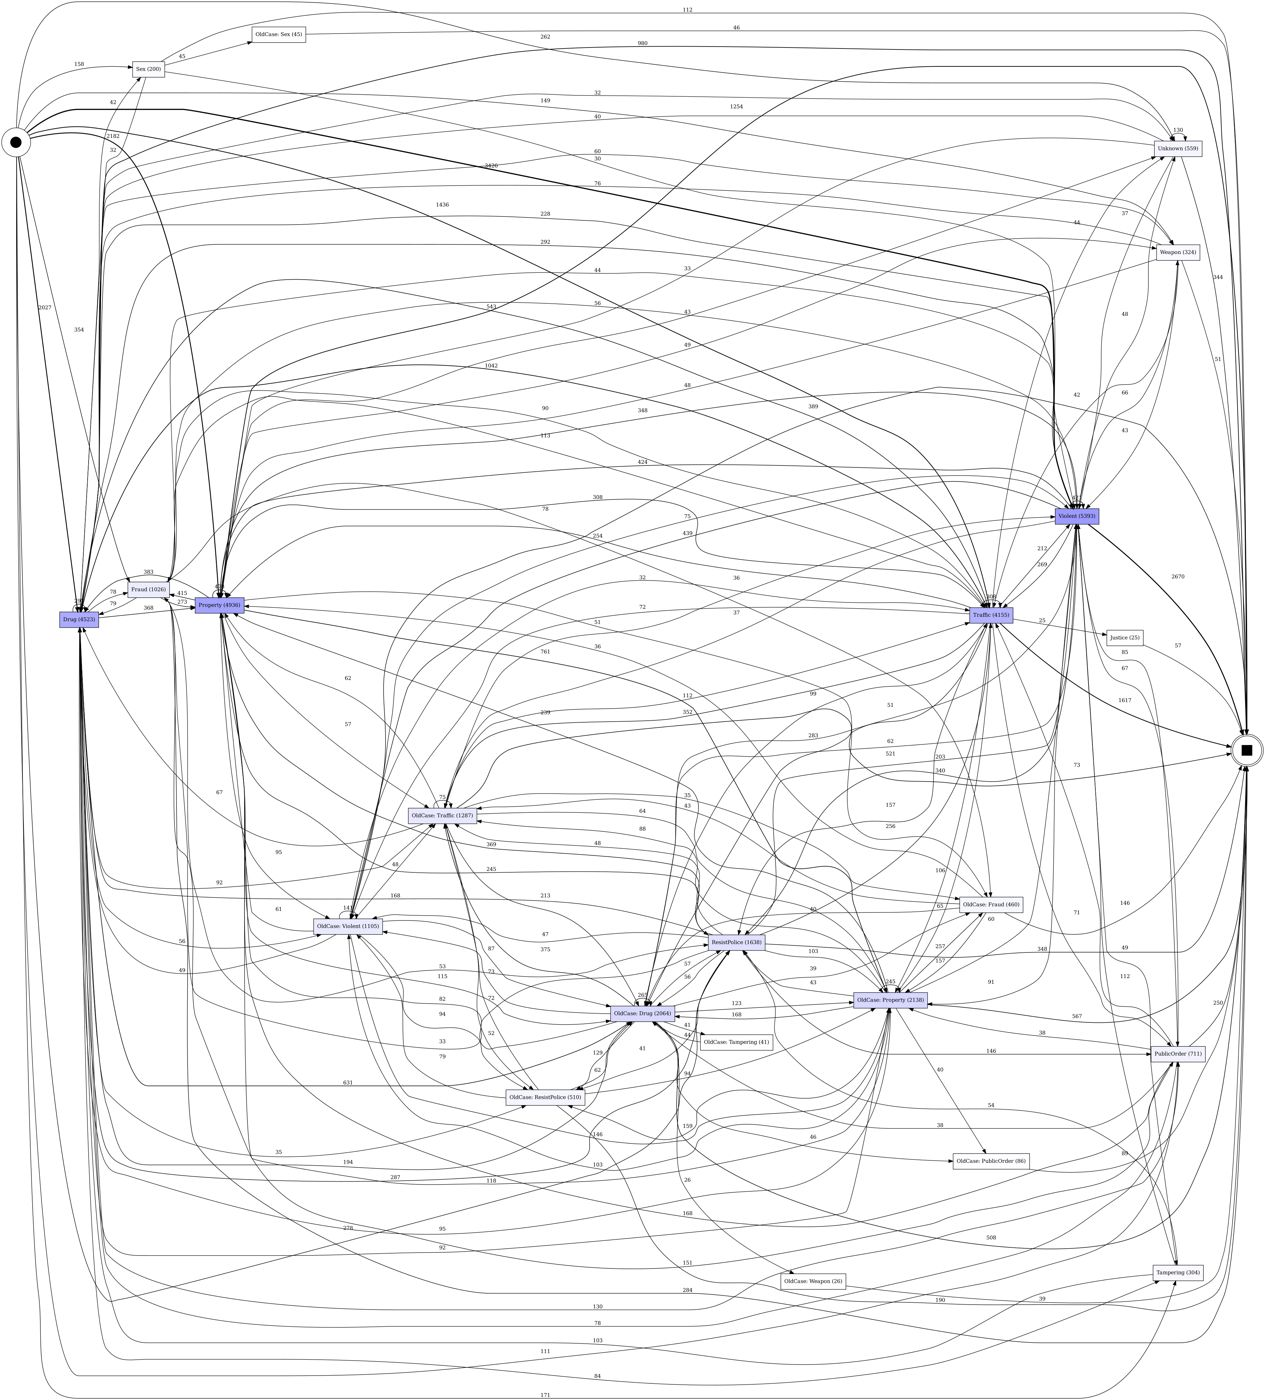

In [4]:
dfg_f, sa_f, ea_f = pm4py.filter_dfg_paths_percentage(dfg, sa, ea, 0.3)
# у pm4py 2.7.23.9 рисунок падает, если начальная/конечная активность не осталась ни на одной дуге — убираем такие
acts_f = {a for k in dfg_f for a in k}
sa_f = {a: n for a, n in sa_f.items() if a in acts_f}
ea_f = {a: n for a, n in ea_f.items() if a in acts_f}
pm4py.save_vis_dfg(dfg_f, sa_f, ea_f, str(FIG / "dfg_frequency_paths30.png"))
show(FIG / "dfg_frequency_paths30.png")

HM 0.9 на всём журнале: мест 57, переходов 329


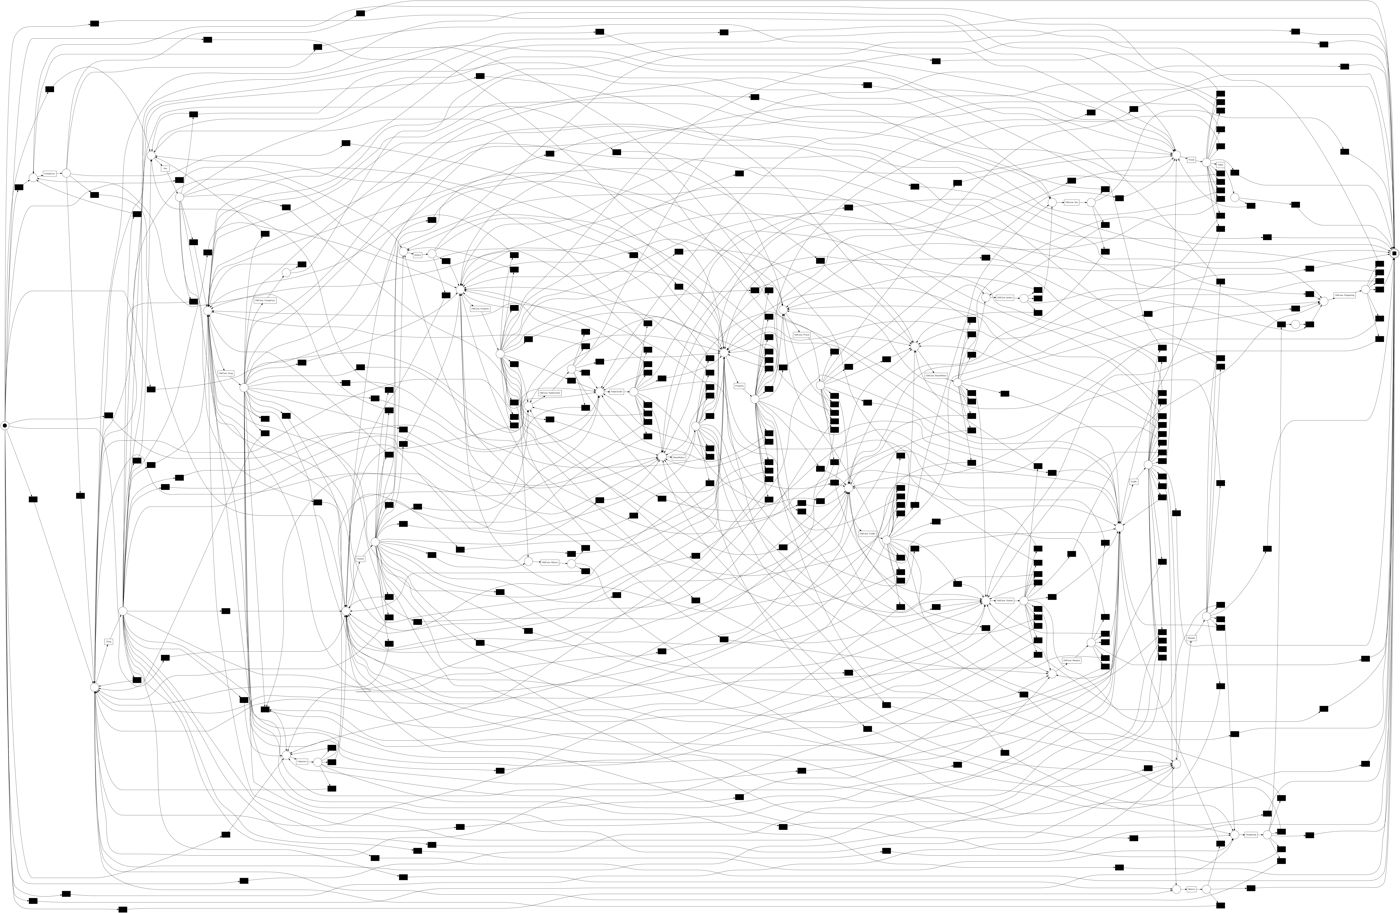

In [5]:
net, im, fm = pm4py.discover_petri_net_heuristics(log, dependency_threshold=0.9)
pm4py.save_vis_petri_net(net, im, fm, str(FIG / "petri_HM_dep0.9.png"))
print(f"HM 0.9 на всём журнале: мест {len(net.places)}, переходов {len(net.transitions)}")
show(FIG / "petri_HM_dep0.9.png")

## Шаг 3. Модели и качество

Названия моделей: `HM_d` — Heuristics Miner с порогом зависимости d; `HM_0.9_min30` — то же, дуги реже 30 раз
отбрасываются; `HM_0.9_and0.95` — то же, параллельность (AND) объявляется только при мере ≥ 0.95; `IM_n` — Inductive Miner с порогом шума n; `*_freq` — модель построена только по людям с
трассой, которая встречается хотя бы у двух человек (проверка — на всех); `ILP` — ILP Miner.

In [6]:
train, test = X.split_people(log)
train_s, test_s = X.sample_cases(train, EVAL_CASES), X.sample_cases(test, EVAL_CASES)


def frequent_train():
    # люди из train, чья трасса (последовательность событий) встречается хотя бы у двух человек
    seq = train.groupby("case:concept:name")["concept:name"].agg(tuple)
    n = seq.map(seq.value_counts())
    return train[train["case:concept:name"].isin(n[n >= 2].index)]


def discover(name):
    if name.startswith("HM_"):
        parts = name.split("_")
        lg = frequent_train() if name.endswith("_freq") else train
        if "min30" in name:
            # параметр есть только в низкоуровневом API pm4py
            from pm4py.algo.discovery.heuristics import algorithm as hm
            P = hm.Variants.CLASSIC.value.Parameters
            return hm.apply(lg, parameters={P.DEPENDENCY_THRESH: float(parts[1]), P.MIN_DFG_OCCURRENCES: 30})
        kw = dict(dependency_threshold=float(parts[1]))
        if "and0.95" in name:
            kw["and_threshold"] = 0.95      # реже объявлять параллельность (AND) между категориями
        return pm4py.discover_petri_net_heuristics(lg, **kw)
    if name.startswith("IM_"):
        lg = frequent_train() if name.endswith("_freq") else train
        return pm4py.discover_petri_net_inductive(lg, noise_threshold=float(name.split("_")[1]))
    if name == "ILP":
        return pm4py.discover_petri_net_ilp(train)
    raise ValueError(name)


models, times = {}, {}
for name in MODELS:
    if name == "ILP" and not RUN_ILP:
        continue
    t0 = time.time()
    models[name] = discover(name)
    times[name] = round(time.time() - t0)
    print(f"{name}: построена за {times[name]} с")

HM_0.9: построена за 0 с


HM_0.95: построена за 0 с


HM_0.99: построена за 0 с
HM_0.9_min30: построена за 0 с


HM_0.9_and0.95: построена за 0 с


IM_0.2: построена за 1 с


IM_0.3: построена за 1 с


IM_0.5: построена за 1 с


HM_0.9_freq: построена за 0 с


IM_0.2_freq: построена за 0 с


In [7]:
quality = X.evaluate(models, train_s, test_s)
quality["discover_sec"] = quality["model"].map(times)
if ALIGN_CASES and "HM_0.9" in models:
    t0 = time.time()
    pa = pm4py.precision_alignments(X.sample_cases(test, ALIGN_CASES), *models["HM_0.9"])
    quality.loc[(quality["model"] == "HM_0.9") & (quality["split"] == "test"), "precision_align"] = round(pa, 4)
    print(f"HM 0.9: precision через выравнивания на {ALIGN_CASES} людях = {pa:.4f} ({time.time() - t0:.0f} с)")
quality.to_csv(OUT / "model_quality.csv", index=False)
quality[quality["split"] == "test"]

{'model': 'HM_0.9', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.9847, 'pct_fit_traces': 89.75, 'precision_tbr': 0.4965, 'f1': 0.6602, 'places': 56, 'transitions': 320, 'silent': 292, 'sec': 9}


{'model': 'HM_0.9', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9821, 'pct_fit_traces': 87.85, 'precision_tbr': 0.543, 'f1': 0.6993, 'places': 56, 'transitions': 320, 'silent': 292, 'sec': 9}


{'model': 'HM_0.95', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.9803, 'pct_fit_traces': 88.3, 'precision_tbr': 0.5102, 'f1': 0.6711, 'places': 56, 'transitions': 302, 'silent': 274, 'sec': 8}


{'model': 'HM_0.95', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9785, 'pct_fit_traces': 86.65, 'precision_tbr': 0.566, 'f1': 0.7172, 'places': 56, 'transitions': 302, 'silent': 274, 'sec': 9}


{'model': 'HM_0.99', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.9735, 'pct_fit_traces': 86.7, 'precision_tbr': 0.5361, 'f1': 0.6915, 'places': 52, 'transitions': 256, 'silent': 230, 'sec': 7}


...

{'model': 'HM_0.9_freq', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9396, 'pct_fit_traces': 69.1, 'precision_tbr': 0.8798, 'f1': 0.9087, 'places': 33, 'transitions': 103, 'silent': 85, 'sec': 3}


{'model': 'IM_0.2_freq', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.9607, 'pct_fit_traces': 66.0, 'precision_tbr': 0.478, 'f1': 0.6384, 'places': 63, 'transitions': 96, 'silent': 71, 'sec': 8}


{'model': 'IM_0.2_freq', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9587, 'pct_fit_traces': 65.8, 'precision_tbr': 0.5523, 'f1': 0.7008, 'places': 63, 'transitions': 96, 'silent': 71, 'sec': 8}


HM 0.9: precision через выравнивания на 2000 людях = 0.5425 (37 с)


,model,split,cases,fitness_tbr,pct_fit_traces,precision_tbr,f1,places,transitions,silent,sec,discover_sec,precision_align
1,HM_0.9,test,2000,0.9821,87.85,0.5430,0.6993,56,320,292,9,0,0.5425
3,HM_0.95,test,2000,0.9785,86.65,0.5660,0.7172,56,302,274,9,0,NaN
5,HM_0.99,test,2000,0.9703,84.45,0.5938,0.7368,52,256,230,7,0,NaN
7,HM_0.9_min30,test,2000,0.9709,83.60,0.6598,0.7857,39,179,159,4,0,NaN
9,HM_0.9_and0.95,test,2000,0.9828,88.35,0.5436,0.7001,57,324,296,9,0,NaN
11,IM_0.2,test,2000,0.9938,94.55,0.3828,0.5527,57,94,65,11,1,NaN
13,IM_0.3,test,2000,0.9859,87.50,0.4136,0.5828,47,84,55,6,1,NaN
15,IM_0.5,test,2000,0.9719,78.45,0.4563,0.6211,39,77,49,3,1,NaN
17,HM_0.9_freq,test,2000,0.9396,69.10,0.8798,0.9087,33,103,85,3,0,NaN
19,IM_0.2_freq,test,2000,0.9587,65.80,0.5523,0.7008,63,96,71,8,0,NaN


## Шаг 4. Сравнение с основным вариантом oldcase_x2

In [8]:
BASE = pd.DataFrame({"model": ["HM_0.5", "HM_0.9", "IM_0.0", "IM_0.2", "IM_0.5"],
                     "fitness_base": [0.9415, 0.9821, 1.0, 0.9938, 0.9716],
                     "precision_base": [0.6136, 0.5430, 0.3688, 0.3828, 0.4563]})
cmp = quality[quality["split"] == "test"][["model", "fitness_tbr", "precision_tbr", "f1"]].merge(BASE, on="model", how="left")
cmp["Δ precision"] = (cmp["precision_tbr"] - cmp["precision_base"]).round(4)
cmp.to_csv(OUT / "compare_with_oldcase_x2.csv", index=False)
cmp

,model,fitness_tbr,precision_tbr,f1,fitness_base,precision_base,Δ precision
0,HM_0.9,0.9821,0.5430,0.6993,0.9821,0.5430,0.0
1,HM_0.95,0.9785,0.5660,0.7172,NaN,NaN,NaN
2,HM_0.99,0.9703,0.5938,0.7368,NaN,NaN,NaN
3,HM_0.9_min30,0.9709,0.6598,0.7857,NaN,NaN,NaN
4,HM_0.9_and0.95,0.9828,0.5436,0.7001,NaN,NaN,NaN
5,IM_0.2,0.9938,0.3828,0.5527,0.9938,0.3828,0.0
6,IM_0.3,0.9859,0.4136,0.5828,NaN,NaN,NaN
7,IM_0.5,0.9719,0.4563,0.6211,0.9716,0.4563,0.0
8,HM_0.9_freq,0.9396,0.8798,0.9087,NaN,NaN,NaN
9,IM_0.2_freq,0.9587,0.5523,0.7008,NaN,NaN,NaN
